# 02 - Spectral exploratory data analysis (EDA), Stage 1

**Question this notebook answers:** in the raw waveform and its spectrum, where (if anywhere)
do bonafide and spoof utterances of the ASVspoof 2019 logical access (LA) corpus differ
statistically, and is any such difference consistent across attack (generator) systems, or
specific to some of them?

**Mode:** the notebook looks for the ASVspoof 2019 LA download at
`configs/data.yaml: dataset.root`; the stored run prints `MODE: REAL DATA`. If the download is
absent, it falls back to a small **synthetic mini-manifest** (synthesised audio plus a fake
protocol file) so the cells still execute; results in that mode are pipeline checks only.

Every plot is an **aggregate distribution over many utterances**, never a single
cherry-picked real/fake pair, and every scalar feature is examined both pooled by class and
conditioned on attack, because a cue that separates one generator but reverses for another
is a property of that generator, not of "fake speech" in general. Feature extraction is done
through `audio_df.audio`, `audio_df.features`, `audio_df.stats` and `audio_df.visualization`,
plus direct calls to `librosa`'s standard spectral descriptors (centroid, bandwidth, rolloff,
flatness, zero-crossing rate (ZCR)). Those descriptors have no equivalent in the project's
`features.py`, which implements the Stage 2 linear-frequency and mel-frequency cepstral
coefficient (LFCC/MFCC) pipeline instead. Root-mean-square (RMS) loudness and silence ratios
are the same nuisance features audited in notebook 01.

In [50]:
from __future__ import annotations

import tempfile
from pathlib import Path


import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from audio_df import audio, data, features, stats
from audio_df import visualization as viz
from audio_df.synthetic import build_synthetic_asvspoof_tree


def _find_repo_root(start: Path) -> Path:
    cur = start.resolve()
    for _ in range(6):
        if (cur / "pyproject.toml").exists():
            return cur
        cur = cur.parent
    raise RuntimeError(f"could not find repo root (pyproject.toml) from {start}")


REPO_ROOT = _find_repo_root(Path.cwd())
pd.set_option("display.width", 120)

In [51]:
%matplotlib inline

In [52]:
_data_cfg_path = REPO_ROOT / "configs" / "data.yaml"
_real_cfg = yaml.safe_load(_data_cfg_path.read_text())
_real_root = Path(_real_cfg["dataset"]["root"])
if not _real_root.is_absolute():
    _real_root = REPO_ROOT / _real_root

USE_REAL_DATA = _real_root.exists() and any(_real_root.rglob("*.flac"))

if USE_REAL_DATA:
    MODE = "REAL DATA"
    cfg = _real_cfg
    cfg["dataset"]["root"] = str(_real_root)
    cfg["dataset"]["protocol_dir"] = str(REPO_ROOT / cfg["dataset"]["protocol_dir"])
    _tmpdir_handle = None
else:
    MODE = "SYNTHETIC MINI-MANIFEST (no ASVspoof download found)"
    _tmpdir_handle = tempfile.TemporaryDirectory(prefix="asvspoof_synth_")
    cfg = build_synthetic_asvspoof_tree(Path(_tmpdir_handle.name), seed=2024)

print(f"MODE: {MODE}")

manifest = data.build_manifest(cfg)
print(f"manifest: {len(manifest)} rows")
manifest.head()

MODE: REAL DATA
manifest: 121461 rows


,utt_id,path,label,speaker_id,attack_id,source_corpus,sample_rate,duration_s,codec,split,language
0,LA_T_1138215,/Users/zuttome/LocalDocs/Learning/College/NUS/...,bonafide,LA_0079,-,ASVspoof2019_LA,16000,3.458063,FLAC,train,en
1,LA_T_1271820,/Users/zuttome/LocalDocs/Learning/College/NUS/...,bonafide,LA_0079,-,ASVspoof2019_LA,16000,4.395187,FLAC,train,en
2,LA_T_1272637,/Users/zuttome/LocalDocs/Learning/College/NUS/...,bonafide,LA_0079,-,ASVspoof2019_LA,16000,2.899500,FLAC,train,en
3,LA_T_1276960,/Users/zuttome/LocalDocs/Learning/College/NUS/...,bonafide,LA_0079,-,ASVspoof2019_LA,16000,2.812562,FLAC,train,en
4,LA_T_1341447,/Users/zuttome/LocalDocs/Learning/College/NUS/...,bonafide,LA_0079,-,ASVspoof2019_LA,16000,3.533187,FLAC,train,en


In [53]:
# For tractability we sample up to N utterances per class per split so this notebook stays
# fast whether MODE is real (121k utterances) or synthetic; the sample is stratified by
# (split, label) so every class/split combination stays represented.
N_PER_CELL = 40
rng = np.random.default_rng(0)


def _stratified_sample(df: pd.DataFrame, n_per_cell: int) -> pd.DataFrame:
    parts = []
    for _, group in df.groupby(["split", "label"], dropna=False):
        take = min(n_per_cell, len(group))
        idx = rng.choice(group.index.to_numpy(), size=take, replace=False)
        parts.append(df.loc[idx])
    return pd.concat(parts).reset_index(drop=True)


eda_df = _stratified_sample(manifest, N_PER_CELL)
print(f"EDA sample: {len(eda_df)} of {len(manifest)} manifest rows")
eda_df.groupby(["split", "label"])["utt_id"].count()

EDA sample: 240 of 121461 manifest rows


split  label   
dev    bonafide    40
       spoof       40
eval   bonafide    40
       spoof       40
train  bonafide    40
       spoof       40
Name: utt_id, dtype: int64

## Waveform amplitude, RMS, duration, and silence distributions

In [54]:
FEATURES_CFG = {
    "sr": 16000,
    "stft": {"n_fft": 512, "hop_length": 160, "win_length": 400, "window": "hann", "center": True},
}

records = []
for row in eda_df.itertuples(index=False):
    x, sr = audio.load_audio(row.path, target_sr=FEATURES_CFG["sr"])
    sil = audio.silence_ratio(x)
    power = features.stft_power(x, FEATURES_CFG)  # [T, K]
    mean_power_spectrum = power.mean(axis=0)  # [K]

    centroid = librosa.feature.spectral_centroid(y=x, sr=sr, n_fft=512, hop_length=160).mean()
    bandwidth = librosa.feature.spectral_bandwidth(y=x, sr=sr, n_fft=512, hop_length=160).mean()
    rolloff = librosa.feature.spectral_rolloff(y=x, sr=sr, n_fft=512, hop_length=160).mean()
    flatness = librosa.feature.spectral_flatness(y=x, n_fft=512, hop_length=160).mean()
    zcr = librosa.feature.zero_crossing_rate(x, frame_length=512, hop_length=160).mean()

    n_bins = mean_power_spectrum.shape[0]
    freqs = np.linspace(0, sr / 2, n_bins)
    low = mean_power_spectrum[freqs < 1000].sum()
    mid = mean_power_spectrum[(freqs >= 1000) & (freqs < 4000)].sum()
    high = mean_power_spectrum[freqs >= 4000].sum()
    total_energy = low + mid + high + 1e-12

    records.append({
        "utt_id": row.utt_id,
        "label": row.label,
        "attack_id": row.attack_id,
        "split": row.split,
        "duration_s": row.duration_s,
        "rms": audio.rms(x),
        "silence_leading": sil["leading"],
        "silence_trailing": sil["trailing"],
        "silence_total": sil["total"],
        "centroid": float(centroid),
        "bandwidth": float(bandwidth),
        "rolloff": float(rolloff),
        "flatness": float(flatness),
        "zcr": float(zcr),
        "band_low_ratio": float(low / total_energy),
        "band_mid_ratio": float(mid / total_energy),
        "band_high_ratio": float(high / total_energy),
        "mean_power_spectrum": mean_power_spectrum,
    })

scalar_df = pd.DataFrame(records)
scalar_df.drop(columns=["mean_power_spectrum"]).head()

,utt_id,label,attack_id,split,duration_s,rms,silence_leading,silence_trailing,silence_total,centroid,bandwidth,rolloff,flatness,zcr,band_low_ratio,band_mid_ratio,band_high_ratio
0,LA_D_7261120,bonafide,-,dev,3.070500,0.122157,0.260544,0.145416,0.405960,1460.208054,1613.883428,3194.906656,0.032836,0.085341,0.927866,0.065082,0.007052
1,LA_D_4246474,bonafide,-,dev,2.215562,0.105307,0.245536,0.234506,0.480042,2155.255417,1820.611122,4236.486486,0.055403,0.163455,0.654241,0.335536,0.010223
2,LA_D_6067855,bonafide,-,dev,2.730750,0.088271,0.433581,0.156276,0.589856,1601.647307,1748.593744,3545.506387,0.033949,0.088582,0.635468,0.363325,0.001207
3,LA_D_3653942,bonafide,-,dev,4.133312,0.088929,0.294195,0.171609,0.465804,1914.453533,1788.881290,3793.327295,0.077378,0.138200,0.800659,0.195898,0.003444
4,LA_D_7944573,bonafide,-,dev,2.044875,0.118847,0.172138,0.217556,0.420992,1797.098757,1774.969357,3612.652439,0.057283,0.141025,0.940171,0.058459,0.001371


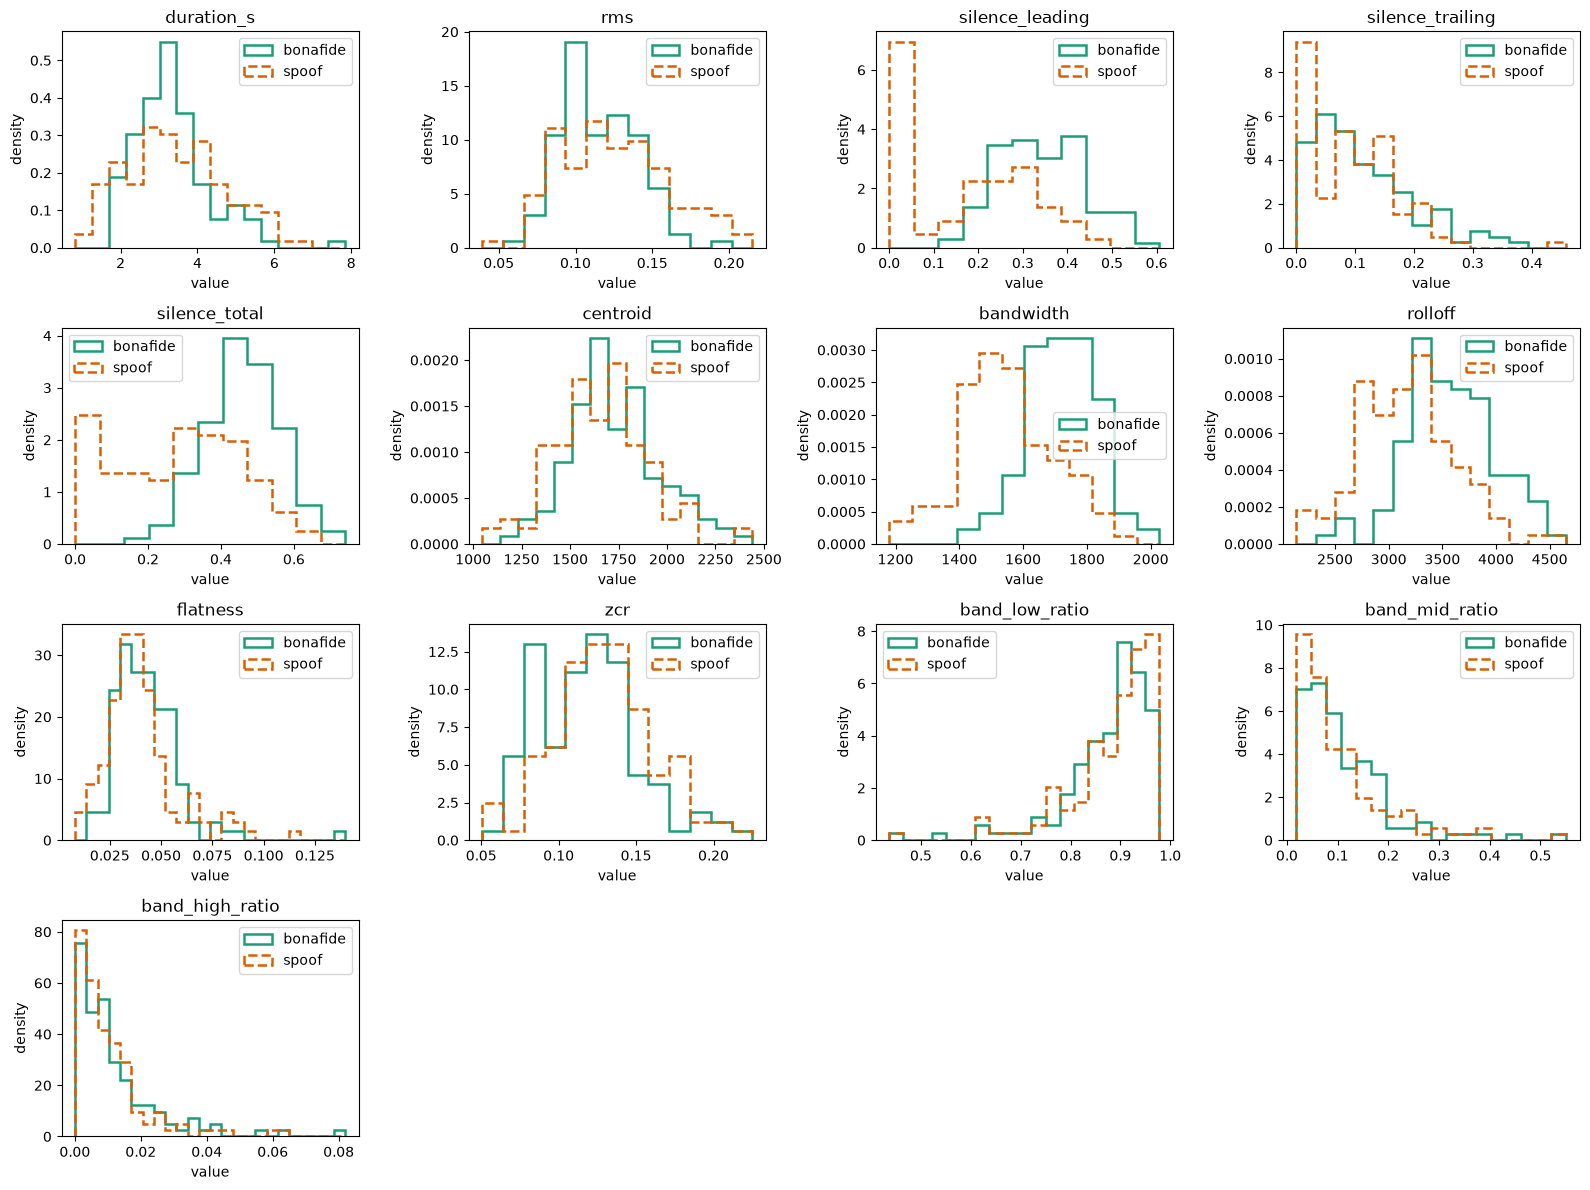

In [55]:
scalar_features = [
    "duration_s", "rms", "silence_leading", "silence_trailing", "silence_total",
    "centroid", "bandwidth", "rolloff", "flatness", "zcr",
    "band_low_ratio", "band_mid_ratio", "band_high_ratio",
]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, feat in zip(axes.ravel(), scalar_features, strict=False):
    values_by_class = {
        label: scalar_df.loc[scalar_df["label"] == label, feat].to_numpy()
        for label in scalar_df["label"].unique()
    }
    viz.plot_class_distributions(values_by_class, ax=ax)
    ax.set_title(feat)
for ax in axes.ravel()[len(scalar_features):]:
    ax.axis("off")
fig.tight_layout()
plt.show()

### Observation
Each panel overlays the pooled bonafide/spoof distribution of one scalar feature across the
240-utterance sample (120 per class, 40 per class in each split). The clearest offsets are:

- **Leading silence:** a large share of spoof clips sit at or near 0, a value bonafide clips
  almost never take; total silence shows the same pile-up at 0.
- **Bandwidth and rolloff:** the spoof distributions sit to the left (lower values) of the
  bonafide distributions.

Duration, RMS, centroid, flatness, ZCR and the three band-energy ratios overlap heavily.

### Inference
An offset panel is a *candidate* statistical cue, not a claim about a universal acoustic
property of synthetic speech. The effect-size table and per-attack plots below quantify and
stress-test each candidate. The silence offsets repeat the shortcut flagged by the notebook 01
leakage audit.

## Effect sizes and bootstrap CIs per scalar feature

In [56]:
effect_rows = []
for feat in scalar_features:
    a = scalar_df.loc[scalar_df["label"] == "spoof", feat].to_numpy()
    b = scalar_df.loc[scalar_df["label"] == "bonafide", feat].to_numpy()
    d = stats.cohens_d(a, b)
    ci_lo, ci_hi = stats.bootstrap_ci(stats.cohens_d, a, b, n_boot=500, seed=0)
    delta = stats.cliffs_delta(a, b)
    effect_rows.append({
        "feature": feat, "cohens_d_spoof_minus_bonafide": d,
        "d_ci_lo": ci_lo, "d_ci_hi": ci_hi, "cliffs_delta": delta,
    })
effect_df = pd.DataFrame(effect_rows)
effect_df

,feature,cohens_d_spoof_minus_bonafide,d_ci_lo,d_ci_hi,cliffs_delta
0,duration_s,0.092955,-0.155598,0.338969,0.049792
1,rms,0.362612,0.105017,0.583063,0.164583
2,silence_leading,-1.420305,-1.733301,-1.156422,-0.636667
3,silence_trailing,-0.239220,-0.501393,0.019574,-0.126528
4,silence_total,-1.276804,-1.556661,-0.992888,-0.604861
5,centroid,-0.298973,-0.563221,-0.042905,-0.151667
6,bandwidth,-1.319079,-1.607455,-1.075334,-0.647222
7,rolloff,-0.934376,-1.208210,-0.686317,-0.497222
8,flatness,-0.156966,-0.393921,0.081761,-0.140833
9,zcr,0.332680,0.077064,0.602346,0.207361


### Observation
`cohens_d` is reported as spoof-minus-bonafide (positive means spoof has the higher mean),
with a bootstrap 95% confidence interval (CI); `cliffs_delta` is the non-parametric companion.
A CI that excludes 0 indicates a reliably non-zero mean difference on this sample. Measured:

- Large negative effects (spoof lower): leading silence (d = -1.42, δ = -0.64), bandwidth
  (d = -1.32, δ = -0.65), total silence (d = -1.28, δ = -0.60) and rolloff (d = -0.93,
  δ = -0.50). All four CIs exclude 0.
- Small positive effects (spoof higher) whose CIs exclude 0: RMS (d = 0.36) and ZCR
  (d = 0.33); centroid shows a small negative effect (d = -0.30, CI -0.56 to -0.04).
- Duration, trailing silence, flatness and the three band ratios have CIs that include 0.

### Inference
Effect size, not p-values, is the quantity reported throughout Stage 1 (see `stats.py`'s
module docstring). With the sample sizes typical of ASVspoof, a t-test would report
"significant" for scientifically negligible differences, while an effect size with a CI says
how large and how reliable each difference is. These numbers come from a 240-clip sample, so
the CIs are wide; they rank candidates rather than settle their size.

## What Cohen's d and Cliff's δ look like

Both numbers above measure **how far apart the two classes are on one feature**. The figure
below draws them for two real features and one made-up example:

- **Top row, Cohen's d.** Histograms of each class, with each class mean as a vertical line.
  *d* is the **gap between the two means** (arrow) divided by the **pooled standard deviation**
  (grey ruler): how many "typical spreads" apart the averages are.
- **Bottom row, Cliff's δ.** Every spoof clip is compared with every bona fide clip. Each cell
  of the grid is one pair: **orange** = the spoof clip has the higher value, **green** = the bona
  fide clip has, **grey** = tie. δ = (share of orange) − (share of green). Both axes are sorted,
  so a clean separation shows up as one big block of a single colour.
- **Columns.**
  - `bandwidth` is a large, well-behaved effect: both measures say spoof is clearly lower.
  - `silence_leading` is skewed: about a quarter of the spoofs sit at or near 0 (the tall orange
    bar). Bona fide clips almost never do, so those spoofs lose every pair: the bottom rows of
    the grid are solid green. *d* is pushed further from 0 by that pile at 0 (−1.42, larger
    than bandwidth's), while δ ranks the two features about equal (−0.64 vs −0.65).
  - **synthetic** has two classes drawn from the *same* distribution, plus 3 extreme outliers
    added to spoof. The outliers pull the spoof mean up, so *d* says spoof is higher (+0.14).
    δ only counts who wins each pair, and the 3 outliers are 3 of 123 clips, so it says spoof is
    very slightly *lower* (−0.07). The two measures disagree even on the sign. That is the
    warning sign to look at the distribution.

**Rule of thumb.** If *d* and δ tell the same story, the difference is real and not driven by a
few extreme clips. If they disagree, look at the distribution itself.

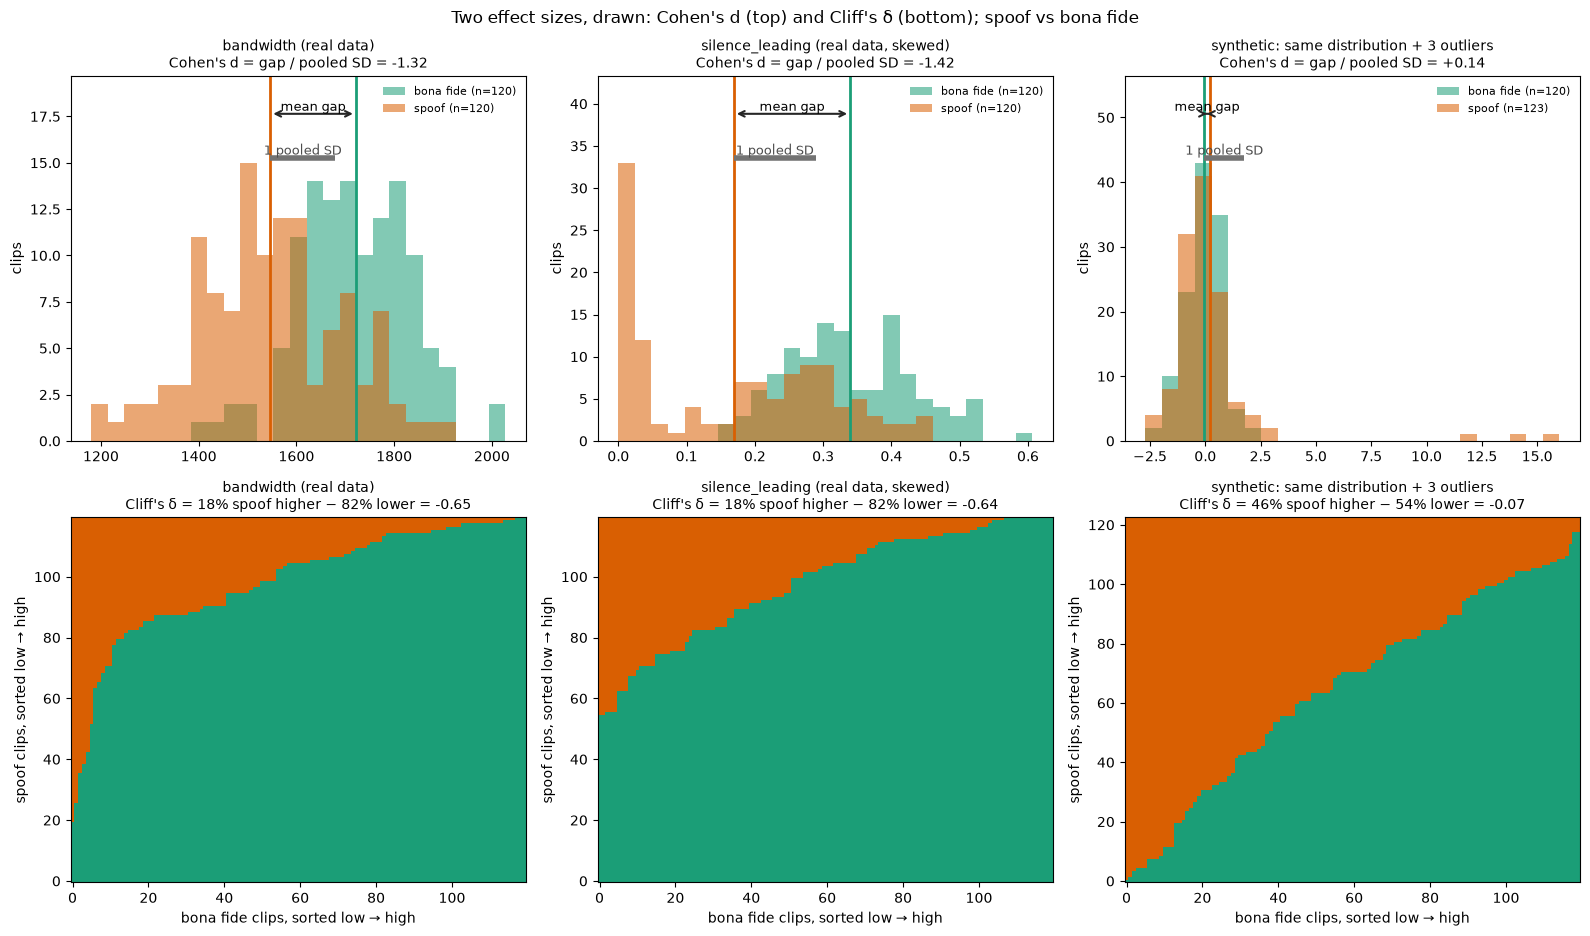

In [57]:
from matplotlib.colors import ListedColormap

C_SPOOF, C_BONA = viz.CLASS_COLORS["spoof"], viz.CLASS_COLORS["bonafide"]
PAIR_CMAP = ListedColormap([C_BONA, "#d9d9d9", C_SPOOF])  # -1 bona wins, 0 tie, +1 spoof wins


def class_values(feat):
    a = scalar_df.loc[scalar_df["label"] == "spoof", feat].to_numpy(dtype=float)
    b = scalar_df.loc[scalar_df["label"] == "bonafide", feat].to_numpy(dtype=float)
    return a, b


def show_cohens_d(ax, a, b, title):
    bins = np.histogram_bin_edges(np.concatenate([a, b]), bins=25)
    ax.hist(b, bins=bins, color=C_BONA, alpha=0.55, label=f"bona fide (n={len(b)})")
    ax.hist(a, bins=bins, color=C_SPOOF, alpha=0.55, label=f"spoof (n={len(a)})")
    mean_a, mean_b = a.mean(), b.mean()
    ax.axvline(mean_b, color=C_BONA, lw=2)
    ax.axvline(mean_a, color=C_SPOOF, lw=2)
    n_a, n_b = len(a), len(b)
    pooled_sd = np.sqrt(((n_a - 1) * a.var(ddof=1) + (n_b - 1) * b.var(ddof=1)) / (n_a + n_b - 2))
    top = ax.get_ylim()[1]
    ax.set_ylim(0, top * 1.25)
    y_gap, y_sd = top * 1.12, top * 0.97
    ax.annotate("", xy=(mean_a, y_gap), xytext=(mean_b, y_gap),
                arrowprops=dict(arrowstyle="<->", color="0.15", lw=1.5))
    ax.text((mean_a + mean_b) / 2, y_gap, " mean gap ", ha="center", va="bottom", fontsize=9)
    x0 = min(mean_a, mean_b)
    ax.plot([x0, x0 + pooled_sd], [y_sd, y_sd], color="0.45", lw=4, solid_capstyle="butt")
    ax.text(x0 + pooled_sd / 2, y_sd, "1 pooled SD", ha="center", va="bottom", fontsize=9, color="0.3")
    d = stats.cohens_d(a, b)
    ax.set_title(f"{title}\nCohen's d = gap / pooled SD = {d:+.2f}", fontsize=10)
    ax.set_ylabel("clips")
    ax.legend(fontsize=8, frameon=False, loc="upper right")
    return d


def show_cliffs_delta(ax, a, b, title):
    pairs = np.sign(np.sort(a)[:, None] - np.sort(b)[None, :])  # rows = spoof, cols = bona fide
    ax.imshow(pairs, cmap=PAIR_CMAP, vmin=-1, vmax=1, aspect="auto", origin="lower",
              interpolation="nearest")
    share_hi, share_lo = (pairs > 0).mean(), (pairs < 0).mean()
    delta = share_hi - share_lo
    assert np.isclose(delta, stats.cliffs_delta(a, b))  # the grid IS the definition
    ax.set_xlabel("bona fide clips, sorted low → high")
    ax.set_ylabel("spoof clips, sorted low → high")
    ax.set_title(f"{title}\nCliff's δ = {share_hi:.0%} spoof higher − {share_lo:.0%} lower = {delta:+.2f}",
                 fontsize=10)
    return delta


# made-up example: same distribution for both classes, plus 3 extreme outliers in spoof
_demo_rng = np.random.default_rng(1)
demo_b = _demo_rng.normal(0, 1, 120)
demo_a = np.concatenate([_demo_rng.normal(0, 1, 120), [12.0, 14.0, 16.0]])

columns = [
    ("bandwidth (real data)",) + class_values("bandwidth"),
    ("silence_leading (real data, skewed)",) + class_values("silence_leading"),
    ("synthetic: same distribution + 3 outliers",) + (demo_a, demo_b),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for col, (title, a, b) in enumerate(columns):
    show_cohens_d(axes[0, col], a, b, title)
    show_cliffs_delta(axes[1, col], a, b, title)
fig.suptitle("Two effect sizes, drawn: Cohen's d (top) and Cliff's δ (bottom); spoof vs bona fide",
             fontsize=12)
fig.tight_layout()
plt.show()

### The same two numbers for every feature, and the link to AUC

Each dot below is one feature from the effect-size table. If *d* and δ agree, the dots fall on a
smooth increasing curve. A dot far off that curve is a feature where outliers or ties make the
two measures disagree.

The printed table checks the identity **δ = 2 · AUC − 1**, using the AUC from the single-feature
table further down (direction "higher = spoof"). It shows Cliff's δ and AUC are the same
information on different scales: δ = 0 is AUC 0.5 (no separation), and |δ| = 1 is AUC 0 or 1.

         feature  cohens_d_spoof_minus_bonafide  cliffs_delta  2*AUC-1 (higher=spoof)
      duration_s                          0.093         0.050                   0.050
             rms                          0.363         0.165                   0.165
 silence_leading                         -1.420        -0.637                  -0.637
silence_trailing                         -0.239        -0.127                  -0.127
   silence_total                         -1.277        -0.605                  -0.605
        centroid                         -0.299        -0.152                  -0.152
       bandwidth                         -1.319        -0.647                  -0.647
         rolloff                         -0.934        -0.497                  -0.497
        flatness                         -0.157        -0.141                  -0.141
             zcr                          0.333         0.207                   0.207
  band_low_ratio                          0.081       

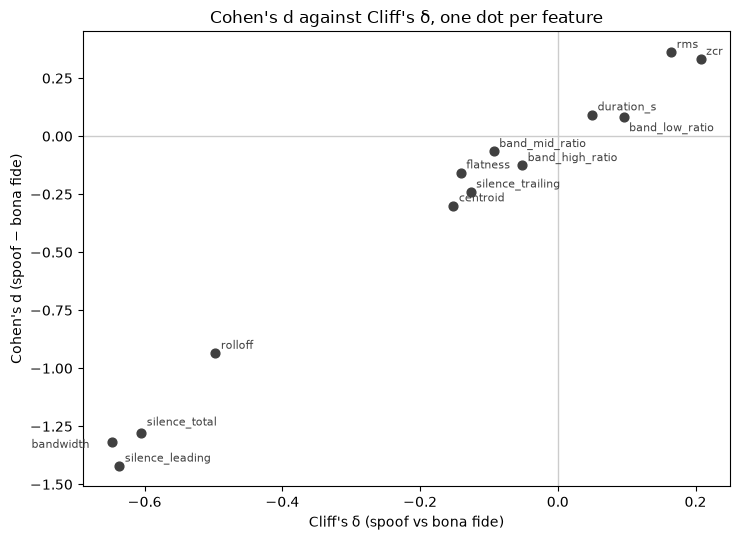

In [58]:
_auc_higher = {
    feat: stats.single_feature_auc(scalar_df[feat].to_numpy(), scalar_df["label"].to_numpy())
    for feat in scalar_features
}
check = effect_df[["feature", "cohens_d_spoof_minus_bonafide", "cliffs_delta"]].copy()
check["2*AUC-1 (higher=spoof)"] = [2 * _auc_higher[f] - 1 for f in check["feature"]]
print(check.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.axhline(0, color="0.8", lw=1)
ax.axvline(0, color="0.8", lw=1)
ax.scatter(check["cliffs_delta"], check["cohens_d_spoof_minus_bonafide"], s=40, color="0.25", zorder=3)
_label_offset = {"bandwidth": (-58, -4), "band_low_ratio": (4, -10), "silence_total": (4, 5)}
for _, row in check.iterrows():
    ax.annotate(row["feature"], (row["cliffs_delta"], row["cohens_d_spoof_minus_bonafide"]),
                xytext=_label_offset.get(row["feature"], (4, 3)), textcoords="offset points",
                fontsize=8, color="0.25")
ax.set_xlabel("Cliff's δ (spoof vs bona fide)")
ax.set_ylabel("Cohen's d (spoof − bona fide)")
ax.set_title("Cohen's d against Cliff's δ, one dot per feature")
fig.tight_layout()
plt.show()

## Single-feature AUC table

**Polarity caveat:** `stats.single_feature_auc` fixes `higher_is_spoof=True`. A feature that
separates the classes with *low* values indicating spoof reports AUC near 0.0, not 1.0 -- so
this table reports both `auc` and `1 - auc` (equivalently `max(auc, 1-auc)` as
`best_direction_auc`), otherwise the most discriminative reversed-polarity features would look
like the least informative ones.

In [59]:
auc_rows = []
for feat in scalar_features:
    values = scalar_df[feat].to_numpy()
    labels = scalar_df["label"].to_numpy()
    auc = stats.single_feature_auc(values, labels)
    auc_rows.append({
        "feature": feat,
        "auc_higher_is_spoof": auc,
        "auc_lower_is_spoof": 1.0 - auc,
        "best_direction_auc": max(auc, 1.0 - auc),
    })
auc_df = pd.DataFrame(auc_rows).sort_values("best_direction_auc", ascending=False)
auc_df

,feature,auc_higher_is_spoof,auc_lower_is_spoof,best_direction_auc
6,bandwidth,0.176389,0.823611,0.823611
2,silence_leading,0.181667,0.818333,0.818333
4,silence_total,0.197569,0.802431,0.802431
7,rolloff,0.251389,0.748611,0.748611
9,zcr,0.603681,0.396319,0.603681
1,rms,0.582292,0.417708,0.582292
5,centroid,0.424167,0.575833,0.575833
8,flatness,0.429583,0.570417,0.570417
3,silence_trailing,0.436736,0.563264,0.563264
10,band_low_ratio,0.547778,0.452222,0.547778


### Observation
`best_direction_auc` ranks features by how separable they are *regardless of direction*; the
`auc_higher_is_spoof` / `auc_lower_is_spoof` columns show which direction carries the signal.
Measured on this sample, four features stand out, all in the "lower means spoof" direction:
bandwidth (0.824), leading silence (0.818), total silence (0.802) and rolloff (0.749). Every
other feature has a best-direction area under the curve (AUC) of 0.604 or less, with duration
lowest at 0.525.

### Inference
A feature near `best_direction_auc = 0.5` is uninformative alone. The top four are candidate
single-feature detectors; two of them (leading and total silence) are nuisance properties of
the recordings rather than of the speech, and the other two (bandwidth, rolloff) are spectral
shape cues that are re-examined per attack below before being trusted as general.

## Mean spectrum with confidence intervals, and per-bin effect size

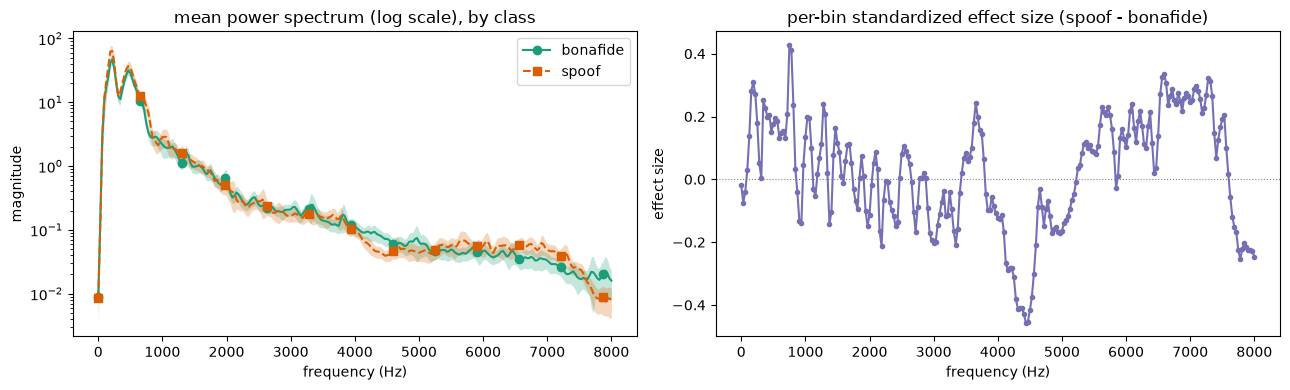

In [60]:
spectra = np.stack(scalar_df["mean_power_spectrum"].to_numpy())
freqs = np.linspace(0, FEATURES_CFG["sr"] / 2, spectra.shape[1])
spectra_by_class = {
    label: spectra[scalar_df["label"].to_numpy() == label]
    for label in scalar_df["label"].unique()
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
viz.plot_mean_spectrum_with_ci(spectra_by_class, freqs, ax=ax1)
ax1.set_yscale("log")
ax1.set_title("mean power spectrum (log scale), by class")

bin_effect = stats.per_bin_effect_size(
    spectra_by_class["spoof"], spectra_by_class["bonafide"]
)
viz.plot_effect_size_per_bin(bin_effect, freqs, ax=ax2)
ax2.set_title("per-bin standardized effect size (spoof - bonafide)")
fig.tight_layout()
plt.show()

### Observation
The left panel is the aggregate mean power spectrum per class with a 95% CI band (never a
single utterance's spectrum). The two class means track each other closely over most of the
band; the clearest visible gap is at the top of the band, where the spoof mean falls off more
steeply towards 8 kHz. The right panel is the per-frequency-bin standardised effect size
(spoof minus bonafide), plotted as a curve rather than as thousands of uncorrected per-bin
significance tests (see `stats.py`'s module docstring: with thousands of bins, per-bin tests
would manufacture "significant" bins by multiple comparisons alone). On this sample the
curve stays within roughly ±0.45: it is most negative (spoof weaker) around 4-5 kHz and near
8 kHz, and positive (spoof stronger) around 5.5-7.5 kHz and below about 1 kHz.

### Inference
Per-bin effects are small (well under the |d| > 1 of the silence and bandwidth features), so
no single frequency band separates the classes on its own in this pooled view. The pattern is
descriptive of this sample and is re-examined per attack next before being treated as a
property of "fake speech" broadly.

## Generator-conditioned views

Same computations as above, conditioned on `attack_id` instead of pooled `label`, so a
cue that separates one attack family but reverses for another is *visible* (crossing lines)
rather than cancelled out in a pooled mean.

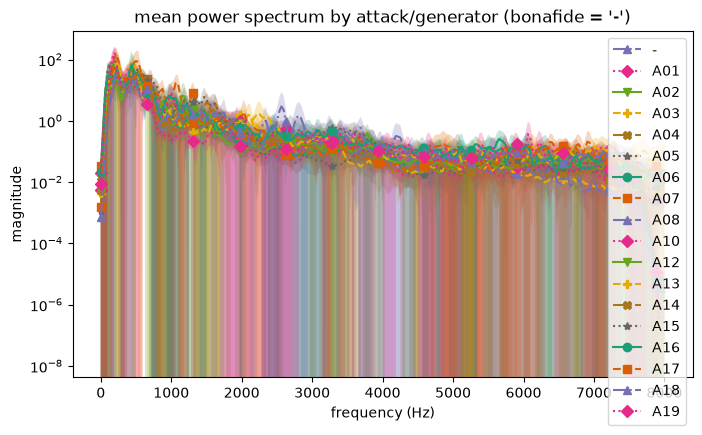

In [61]:
spectra_by_attack = {}
for attack in sorted(scalar_df["attack_id"].unique()):
    mask = scalar_df["attack_id"].to_numpy() == attack
    if mask.sum() < 2:
        continue
    spectra_by_attack[attack] = spectra[mask]

fig, ax = plt.subplots(figsize=(8, 4.5))
viz.plot_mean_spectrum_by_attack(spectra_by_attack, freqs, ax=ax)
ax.set_yscale("log")
ax.set_title("mean power spectrum by attack/generator (bonafide = '-')")
plt.show()

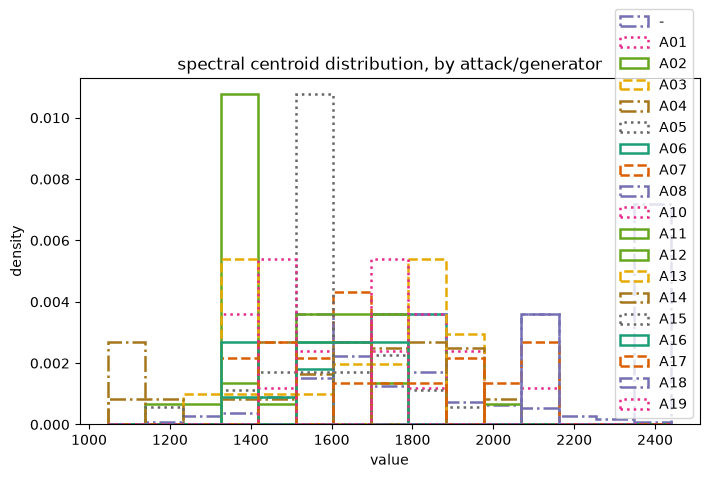

Per-attack mean spectral centroid (Hz):
attack_id
A11    1399.588726
A14    1513.144167
A02    1577.314090
A15    1578.241329
A19    1584.328814
A16    1584.781515
A05    1606.370647
A13    1611.569933
A04    1628.719610
A07    1642.040618
A10    1653.108940
A12    1653.728345
A03    1658.724513
A06    1685.781147
-      1733.325039
A01    1749.225629
A17    1804.862430
A08    1829.689423
A18    2291.764239
Name: centroid, dtype: float64


In [62]:
fig, ax = plt.subplots(figsize=(8, 4.5))
centroid_by_attack = {
    attack: scalar_df.loc[scalar_df["attack_id"] == attack, "centroid"].to_numpy()
    for attack in sorted(scalar_df["attack_id"].unique())
}
viz.plot_class_distributions_by_attack(centroid_by_attack, ax=ax)
ax.set_title("spectral centroid distribution, by attack/generator")
plt.show()

print("Per-attack mean spectral centroid (Hz):")
print(scalar_df.groupby("attack_id")["centroid"].mean().sort_values())

### Observation
The by-attack views show each attack system separately rather than averaged into one "spoof"
class. The per-attack sample is small (120 spoof clips spread over the attacks, and A09 has no
clips in this sample), so the mean-spectrum panel is dominated by overlapping CI bands and is
hard to read; the centroid table is the clearer evidence. The measured per-attack mean
centroids sit on **both sides** of bonafide (`-`, 1,733 Hz): A18 (2,292 Hz), A08 (1,830 Hz),
A17 (1,805 Hz) and A01 (1,749 Hz) are higher, while the other attacks are lower, down to A14
(1,513 Hz) and A11 (1,400 Hz).

### Inference
Because some attacks push the centroid up relative to bonafide and others push it down,
spectral centroid is not a general property of synthetic speech; a pooled real-vs-fake
comparison averages the two directions towards the middle, which is consistent with the
small pooled centroid effect above (d = -0.30). One explanation is that each generator's own
processing chain shapes the spectrum differently; with roughly half a dozen clips per attack
that remains a hypothesis. When the notebook runs in synthetic mode, the mini-corpus is built
with per-attack high-shelf gains of opposite sign (see
`audio_df.synthetic.build_synthetic_asvspoof_tree`) so the same reversal appears by
construction; that run demonstrates the method, not a finding about ASVspoof.

## Single example spectrograms (context only, not evidence)

A single spectrogram pair is shown only as visual context for what the mean-spectrum plots
above summarise; it is **not** evidence of a class difference on its own. In the stored run the
pair is one bonafide clip and one A03 spoof clip; the spoof clip has a much shorter silent
lead-in before speech starts, the per-clip version of the leading-silence effect above.

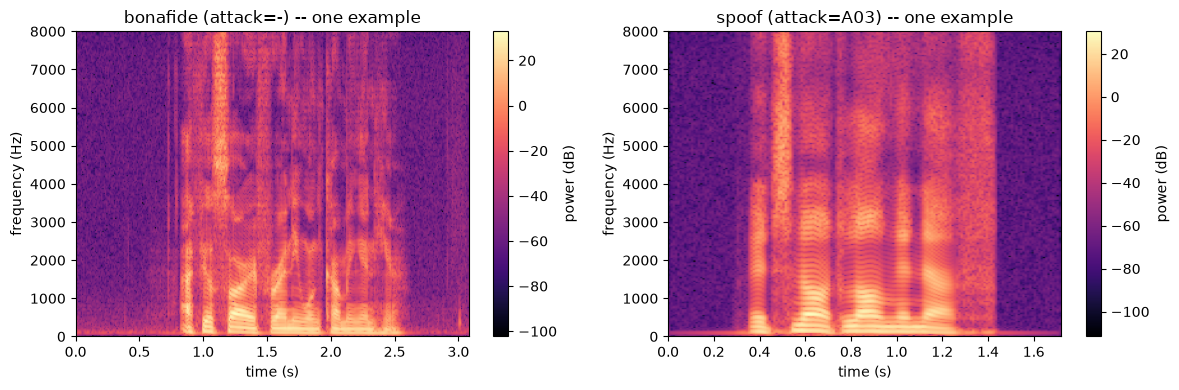

In [63]:
example_bonafide = eda_df[eda_df["label"] == "bonafide"].iloc[0]
example_spoof = eda_df[eda_df["label"] == "spoof"].iloc[0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for ax, row in [(ax1, example_bonafide), (ax2, example_spoof)]:
    x, sr = audio.load_audio(row["path"], target_sr=FEATURES_CFG["sr"])
    power = features.stft_power(x, FEATURES_CFG)  # [T, K]
    viz.plot_spectrogram(power.T, sr, hop_length=FEATURES_CFG["stft"]["hop_length"], ax=ax)
    ax.set_title(f"{row['label']} (attack={row['attack_id']}) -- one example")
fig.tight_layout()
plt.show()

In [64]:
print(f"MODE was: {MODE}")

MODE was: REAL DATA


## Summary

On this 240-clip sample of the real corpus, the strongest pooled cues are leading and total
silence (best-direction AUC 0.818 and 0.802) and two spectral-shape features, bandwidth and
rolloff (0.824 and 0.749), all lower for spoof. The silence cues are nuisance properties
already flagged in notebook 01. Per-bin spectral effects are small, and the spectral centroid
moves in opposite directions for different attacks, so it is attack-specific rather than a
general cue. No feature examined here is claimed to be a universal artifact of synthetic
speech; each is a candidate cue whose generality is what the by-attack views test, and the
small per-attack sample limits how far that test goes.